# 01 Data and on-target check: GSE114273 (siPARP1 / siPARP2 in LNCaP)

**Purpose:** prepare the protein-coding gene annotation for DESeq2 (notebook 03) and check knockdown of the intended targets.

**Inputs** (`data/datasets/GSE114273/raw/`): `Human.GRCh38.p13.annot.tsv`, `GSE114273_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz`

**Outputs**
- `processed/GSE114273_gene_mapping_protein_coding.tsv` (19,227 genes) → notebook 03
- `results/GSE114273/tables/GSE114273_knockdown_tpm.tsv`, `results/GSE114273/figures/GSE114273_knockdown_tpm.png`

**Dataset-specific inputs:** `sample_labels` (sample-sheet cell) and `targets` (on-target cell).

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print(sys.executable)

/home/piets/sirna_shrna_offtargets/.venv/bin/python


In [2]:
## Paths and sample sheet: GSM accession -> sample label (<condition>_rep<N>, as in all notebooks)
raw_dir = Path("../../data/datasets/GSE114273/raw")
processed_dir = Path("../../data/datasets/GSE114273/processed")
figures_dir = Path("../../results/GSE114273/figures")

# siRNA arm only; the GEO files also hold 8 PARP-inhibitor samples (GSM3138699-706)
sample_labels = {
    "GSM3138707": "siNC_rep1",      "GSM3138708": "siNC_rep2",
    "GSM3138709": "siPARP1-A_rep1", "GSM3138710": "siPARP1-A_rep2",
    "GSM3138711": "siPARP1-B_rep1", "GSM3138712": "siPARP1-B_rep2",
    "GSM3138713": "siPARP2-A_rep1", "GSM3138714": "siPARP2-A_rep2",
    "GSM3138715": "siPARP2-B_rep1", "GSM3138716": "siPARP2-B_rep2",
}

In [3]:
## Load the NCBI gene annotation and the GEO TPM matrix (both NCBI GeneID-based, GRCh38.p13)
annot_raw = pd.read_csv(
    raw_dir / "Human.GRCh38.p13.annot.tsv", sep="\t",
    usecols=["GeneID", "EnsemblGeneID", "Symbol", "GeneType", "Description"],
)
counts_tpm_geo = pd.read_csv(raw_dir / "GSE114273_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz", sep="\t")

print("Annotation:", annot_raw.shape)          # expect (39376, 5)
print("TPM (all 18 samples):", counts_tpm_geo.shape)   # expect (39376, 19)

# Checks: unique gene IDs, the same genes in both files, all 10 siRNA samples present
assert annot_raw["GeneID"].is_unique and counts_tpm_geo["GeneID"].is_unique
assert set(annot_raw["GeneID"]) == set(counts_tpm_geo["GeneID"])
assert set(sample_labels) <= set(counts_tpm_geo.columns), "a GSM in sample_labels is missing from the TPM file"

annot_raw["GeneType"].value_counts().head(6)

Annotation: (39376, 5)
TPM (all 18 samples): (39376, 19)


GeneType
protein-coding    19416
ncRNA             15480
pseudo             1392
snoRNA              541
tRNA                437
other               388
Name: count, dtype: int64

In [4]:
## Protein-coding genes that have an Ensembl ID (needed to link to DESeq2 results and TargetScan 3'UTRs)
is_pc = annot_raw["GeneType"] == "protein-coding"
has_ensembl = annot_raw["EnsemblGeneID"].notna()

annot_pc = annot_raw[is_pc & has_ensembl].copy()
print("Protein-coding:", is_pc.sum())                                  # expect 19416
print("... without Ensembl ID (dropped):", (is_pc & ~has_ensembl).sum())   # expect 178
print("... kept:", len(annot_pc))                                      # expect 19238

Protein-coding: 19416
... without Ensembl ID (dropped): 178
... kept: 19238


In [5]:
## Some Ensembl IDs belong to two NCBI genes. Explicit rule, applied in order:
##   1. drop 'readthrough' entries (fusion transcripts spanning two neighbouring genes)
##   2. drop uncharacterised 'LOC' entries (no official gene symbol yet)
## Anything still duplicated needs a manual decision -> stop with an error.

# Rule 1
dup = annot_pc["EnsemblGeneID"].duplicated(keep=False)
readthrough = annot_pc["Description"].str.contains("readthrough", case=False, na=False)
removed_readthrough = annot_pc[dup & readthrough]
annot_pc = annot_pc[~(dup & readthrough)]

# Rule 2 (re-check duplicates: rule 1 already resolved most)
dup = annot_pc["EnsemblGeneID"].duplicated(keep=False)
loc_gene = annot_pc["Symbol"].str.startswith("LOC", na=False)
removed_loc = annot_pc[dup & loc_gene]
annot_pc = annot_pc[~(dup & loc_gene)]

remaining = annot_pc.loc[annot_pc["EnsemblGeneID"].duplicated(keep=False), ["GeneID", "Symbol", "EnsemblGeneID"]]
assert remaining.empty, f"Unresolved duplicate Ensembl IDs, decide manually:\n{remaining}"

annot_pc = annot_pc[["GeneID", "EnsemblGeneID", "Symbol", "GeneType", "Description"]].reset_index(drop=True)
print("Removed: readthrough", len(removed_readthrough), "| LOC", len(removed_loc))   # expect 10 | 1
print("annot_pc:", annot_pc.shape)                                                     # expect (19227, 5)
pd.concat([removed_readthrough, removed_loc])[["GeneID", "Symbol", "EnsemblGeneID", "Description"]]

Removed: readthrough 10 | LOC 1
annot_pc: (19227, 5)


,GeneID,Symbol,EnsemblGeneID,Description
471,100532736,MICOS10-NBL1,ENSG00000158747,MICOS10-NBL1 readthrough
2222,100534012,TNFAIP8L2-SCNM1,ENSG00000163156,TNFAIP8L2-SCNM1 readthrough
4438,100302652,GPR75-ASB3,ENSG00000115239,GPR75-ASB3 readthrough
5722,100526832,PHOSPHO2-KLHL23,ENSG00000213160,PHOSPHO2-KLHL23 readthrough
12422,107080638,TBC1D7-LOC100130357,ENSG00000145979,TBC1D7-LOC100130357 readthrough
15140,109504726,ERV3-1-ZNF117,ENSG00000152926,ERV3-1-ZNF117 readthrough
23545,106707243,PRH1-TAS2R14,ENSG00000212127,PRH1-TAS2R14 readthrough
24993,100533183,ZNF664-RFLNA,ENSG00000178882,ZNF664-RFLNA readthrough
28032,106821730,BUB1B-PAK6,ENSG00000137843,BUB1B-PAK6 readthrough
33938,4207,BORCS8-MEF2B,ENSG00000213999,BORCS8-MEF2B readthrough


In [6]:
## Save: input for notebook 03 (DESeq2)
annot_pc.to_csv(processed_dir / "GSE114273_gene_mapping_protein_coding.tsv", sep="\t", index=False)
print("Saved:", annot_pc.shape)

Saved: (19227, 5)


In [7]:
## TPM for the 10 siRNA samples and the protein-coding genes: Ensembl ID as index, readable sample labels
## (descriptive use only, for the on-target check; DE uses raw counts in notebook 03)
counts_tpm_pc = (
    annot_pc[["GeneID", "EnsemblGeneID"]]
    .merge(counts_tpm_geo[["GeneID"] + list(sample_labels)], on="GeneID", how="inner", validate="one_to_one")
    .set_index("EnsemblGeneID")
    .drop(columns="GeneID")
    .rename(columns=sample_labels)
)

In [8]:
print("Shape:", counts_tpm_pc.shape)                                  # expect (19227, 10)
print("Missing values:", counts_tpm_pc.isna().sum().sum())            # expect 0
print("Negative values:", (counts_tpm_pc < 0).sum().sum())            # expect 0
print("\nShare of TPM in protein-coding genes (%):")
print((counts_tpm_pc.sum() / 1e6 * 100).round(1))
counts_tpm_pc.head()

Shape: (19227, 10)
Missing values: 0
Negative values: 0

Share of TPM in protein-coding genes (%):
siNC_rep1         82.2
siNC_rep2         85.2
siPARP1-A_rep1    82.5
siPARP1-A_rep2    83.0
siPARP1-B_rep1    80.6
siPARP1-B_rep2    81.4
siPARP2-A_rep1    82.5
siPARP2-A_rep2    82.7
siPARP2-B_rep1    85.5
siPARP2-B_rep2    83.3
dtype: float64


,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
EnsemblGeneID,,,,,,,,,,
ENSG00000186092,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
ENSG00000284733,0.00000,0.00000,0.11700,0.00000,0.00000,0.00000,0.00000,0.00000,0.12570,0.00000
ENSG00000284662,0.01957,0.03683,0.03803,0.02007,0.02057,0.02181,0.03558,0.03497,0.02042,0.03697
ENSG00000187634,21.28000,23.77000,17.28000,15.92000,25.34000,24.84000,20.35000,18.93000,13.07000,15.33000
ENSG00000188976,98.92000,111.50000,112.20000,109.70000,111.50000,101.90000,147.10000,139.00000,126.30000,130.80000


In [9]:
## On-target check: % of siNC expression remaining (TPM), for every siRNA x target gene
## Descriptive only: with n = 2 this is a sanity check, not a statistical test (CLAUDE.md)
targets = {"siPARP1-A": "PARP1", "siPARP1-B": "PARP1", "siPARP2-A": "PARP2", "siPARP2-B": "PARP2"}

target_ids = annot_pc.set_index("Symbol").loc[sorted(set(targets.values())), "EnsemblGeneID"]
condition = counts_tpm_pc.columns.str.rsplit("_", n=1).str[0]      # "siPARP1-A_rep1" -> "siPARP1-A"

rows = []
for sirna, intended_gene in targets.items():
    for gene, ensembl_id in target_ids.items():
        tpm = counts_tpm_pc.loc[ensembl_id]
        sinc_mean = tpm[condition == "siNC"].mean()
        sirna_tpm = tpm[condition == sirna]
        pct_per_replicate = sirna_tpm / sinc_mean * 100
        rows.append({
            "siRNA": sirna,
            "gene": gene,
            "intended_target": gene == intended_gene,
            "siNC_mean_TPM": sinc_mean,
            "siRNA_mean_TPM": sirna_tpm.mean(),
            "pct_remaining_mean": sirna_tpm.mean() / sinc_mean * 100,
            "pct_remaining_min": pct_per_replicate.min(),
            "pct_remaining_max": pct_per_replicate.max(),
        })

knockdown_tpm = pd.DataFrame(rows)
knockdown_tpm.round(1)

,siRNA,gene,intended_target,siNC_mean_TPM,siRNA_mean_TPM,pct_remaining_mean,pct_remaining_min,pct_remaining_max
0,siPARP1-A,PARP1,True,223.0,2.4,1.1,1.1,1.1
1,siPARP1-A,PARP2,False,23.2,18.4,79.3,76.7,81.8
2,siPARP1-B,PARP1,True,223.0,4.2,1.9,1.9,1.9
3,siPARP1-B,PARP2,False,23.2,16.2,69.7,67.7,71.6
4,siPARP2-A,PARP1,False,223.0,175.6,78.7,76.1,81.3
5,siPARP2-A,PARP2,True,23.2,2.6,11.0,9.6,12.4
6,siPARP2-B,PARP1,False,223.0,78.9,35.4,32.6,38.1
7,siPARP2-B,PARP2,True,23.2,1.4,6.0,5.1,7.0


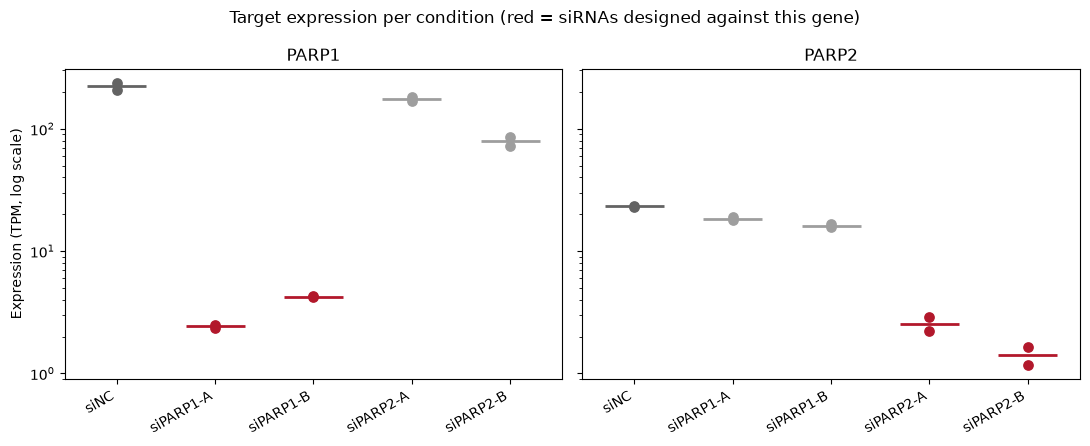

In [10]:
## TPM of each target gene per condition: dots = replicates, bar = mean (log scale)
conditions = list(dict.fromkeys(condition))          # unique, in sample-sheet order

fig, axes = plt.subplots(1, len(target_ids), figsize=(5.5 * len(target_ids), 4.5), sharey=True)
for ax, (gene, ensembl_id) in zip(np.atleast_1d(axes), target_ids.items()):
    tpm = counts_tpm_pc.loc[ensembl_id]
    for i, cond in enumerate(conditions):
        values = tpm[condition == cond]
        is_target = targets.get(cond) == gene
        colour = "#b2182b" if is_target else ("#636363" if cond == "siNC" else "#9e9e9e")
        ax.scatter([i] * len(values), values, s=45, color=colour, zorder=3)
        ax.hlines(values.mean(), i - 0.3, i + 0.3, color=colour, lw=2)
    ax.set_yscale("log")
    ax.set_xticks(range(len(conditions)), conditions, rotation=30, ha="right")
    ax.set_title(gene)
np.atleast_1d(axes)[0].set_ylabel("Expression (TPM, log scale)")
fig.suptitle("Target expression per condition (red = siRNAs designed against this gene)")
plt.tight_layout()
fig.savefig(figures_dir / "GSE114273_knockdown_tpm.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
## Save the knockdown table to results/ (write-up evidence for the on-target check)
tables_dir = Path("../../results/GSE114273/tables")
knockdown_tpm.to_csv(tables_dir / "GSE114273_knockdown_tpm.tsv", sep="\t", index=False)
print("Saved:", knockdown_tpm.shape)        # expect (8, 8)

Saved: (8, 8)


## Summary

- **Annotation:** 19,416 protein-coding genes → 178 without Ensembl ID dropped → 11 duplicate Ensembl IDs resolved by rule (10 readthrough, 1 LOC) → **19,227 genes**, unique Ensembl IDs.
- **Knockdown (TPM, % of siNC remaining):** siPARP1-A 1.1 % and siPARP1-B 1.9 % (PARP1); siPARP2-A 11.0 % and siPARP2-B 6.0 % (PARP2). Agrees with DESeq2 (notebook 03).
- **Cross-effects:** siPARP2-B also lowers PARP1 to 35 %; the other non-target values are 70–80 %.
- Descriptive only (n = 2); no statistical test.